# Train the card detector

Choose boxes, corners, quadrilaterals, or segmentation masks with a shared frozen DINOv3 ConvNeXt Tiny backbone. Set `fast_dev_run = False` for full training.


In [17]:
import json
from pathlib import Path
from datetime import datetime
from dataclasses import asdict

import cv2
import numpy as np
import lightning.pytorch as pl
import wandb
import torch
from lightning.pytorch.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger
from set_master.training.logging import create_wandb_logger

from set_master.training.augmentation import AugmentationConfig
from set_master.training.data import CardDataModule
from set_master.training.callbacks import EpochEvaluation
from set_master.training.model import DEFAULT_REPO, DEFAULT_WEIGHTS
from set_master.training.config import DetectorConfig, DetectorVariant
from set_master.training.models.factory import create_detector, load_detector
from set_master.training.evaluation import prediction_overlay
from set_master.paths import PROJECT_ROOT, REAL_TESTSET_DIR, RUNS_DIR, SYNTHETIC_DATASETS_DIR, AUGMENTATION_PRESET_PATH
from set_master.visualization import display_image

print(f'Project: {PROJECT_ROOT}')
print(f'CUDA available: {torch.cuda.is_available()}')


Project: /home/florian/src/python/set-master
CUDA available: True


## Settings

Set `dataset_run` to the run you want to train on. With `val_data = None`, 10% of images are reserved for validation. Training samples a new subset each epoch; set `train_images_per_epoch = None` to use all training images.

Choose `variant`. The experiment name includes its type and timestamp. `CORNERS` predicts corner heatmaps; `QUADRILATERAL` directly regresses eight normalized corner coordinates from the box head's region features with Smooth L1 loss. Both use existing corner annotations and support polygon metrics, overlays, and rectified crops. `ORIENTED` uses oriented-box annotations. `SEMANTIC` predicts the union of card pixels with BCE and Dice losses; `INSTANCE` uses Mask R-CNN to predict a mask for each detected card. Both mask heads use 128 channels and existing segmentation polygons. Checkpoints use foreground IoU for semantic masks and mask mAP for instance masks.

The selected tabletop scenes contain 2,000 training and 200 validation images, with separate source-background pools. Each epoch uses 500 training images and a fixed 50-image validation subset. Set `val_images_per_epoch = None` to evaluate the full validation pool. Scene scales cover the real annotations with extra room for distant and close-up cards.


In [18]:
variant = DetectorVariant.SEMANTIC  # BOX, ORIENTED, CORNERS, QUADRILATERAL, SEMANTIC, or INSTANCE
experiment_name = f'{variant.value}_{datetime.now():%Y%m%d_%H%M%S_%f}'
dataset_run = 'tabletop_scenes_v2_train'
train_data = SYNTHETIC_DATASETS_DIR / dataset_run
val_data = SYNTHETIC_DATASETS_DIR / 'tabletop_scenes_v2_validation'
val_fraction = 0.1
train_images_per_epoch = 500
val_images_per_epoch = 50
test_data = REAL_TESTSET_DIR
augment = True
augmentation_preset_path = AUGMENTATION_PRESET_PATH
augmentation_config = AugmentationConfig.load(augmentation_preset_path)
wandb_url = 'http://localhost:8080'
wandb_project = 'set-master'
wandb_entity = None

early_stopping_patience = 5
early_stopping_min_delta = 0.001
eval_score_threshold = 0.75
eval_iou_threshold = 0.5
validation_overlay_ids = None  # All validation images; set a list of IDs to limit.
test_overlay_ids = None  # All real images; set a list of IDs to limit.

weights_path = DEFAULT_WEIGHTS
repo_path = DEFAULT_REPO
output_dir = RUNS_DIR / 'card_detector' / variant.value / experiment_name
resume_checkpoint = None

batch_size = 6
num_workers = 2
epochs = 20
learning_rate = 1e-3
weight_decay = 1e-4
min_size = 640
max_size = 1280
accelerator = 'gpu'
precision = '32-true'
seed = 42
fast_dev_run = False


AttributeError: 'str' object has no attribute 'value'

## Data preview

Ground-truth boxes are green.


Seed set to 42


Training pool: 2000 images
Training images per epoch: 500
Validation pool: 200 images
Validation images per epoch: 50
Training/validation batches: 84/9
Real test images: 13
Validation image IDs: [3, 6, 10, 17, 22, 26, 28, 32, 39, 43, 44, 57, 62, 65, 72, 75, 76, 78, 82, 85, 86, 89, 91, 94, 98, 103, 106, 107, 118, 120, 122, 140, 143, 144, 147, 153, 154, 161, 164, 166, 169, 176, 179, 181, 182, 189, 193, 197, 198, 200]


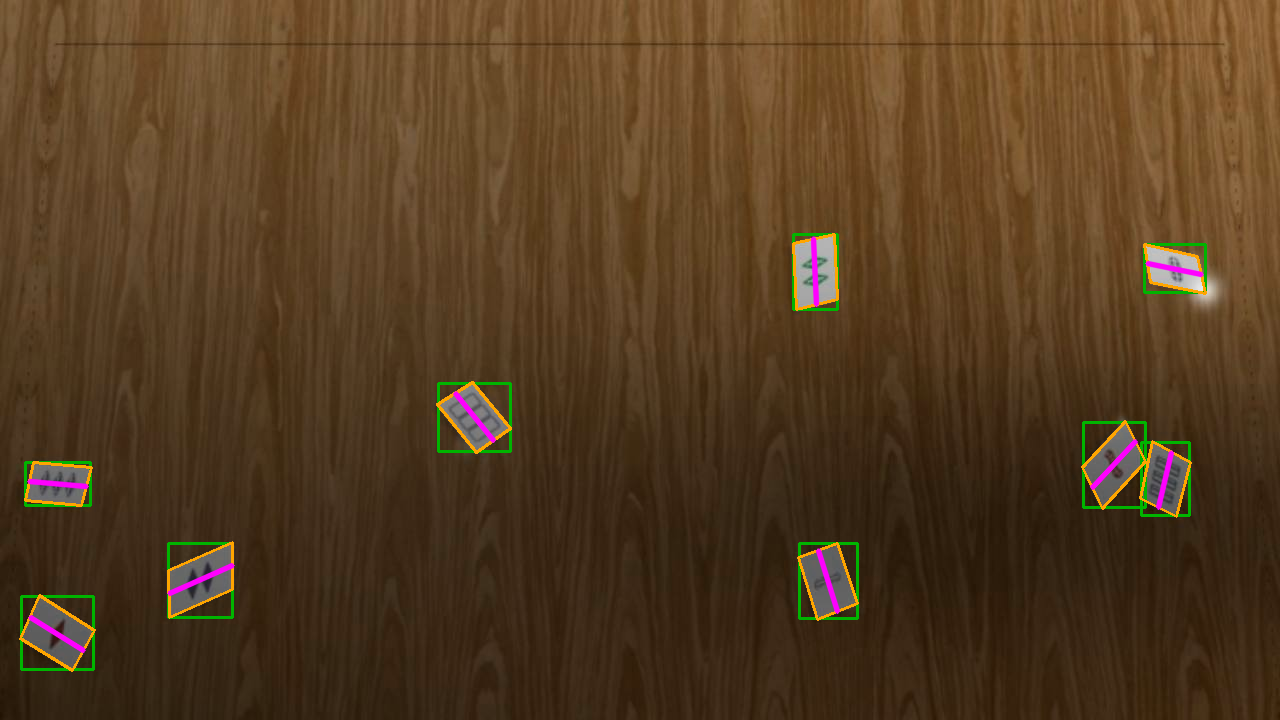

In [ ]:
if not (train_data / 'annotations.json').is_file():
    raise FileNotFoundError('Choose a generated dataset in train_data, or create one with generate_synthetic_dataset.ipynb.')
if batch_size < 1 or num_workers < 0 or not 0 < min_size <= max_size:
    raise ValueError('Require batch_size > 0, num_workers >= 0 and 0 < min_size <= max_size.')

pl.seed_everything(seed, workers=True)
data = CardDataModule(
    train_root=train_data, val_root=val_data, batch_size=batch_size,
    num_workers=num_workers, val_fraction=val_fraction, seed=seed, variant=variant, test_root=test_data, augment=augment,
    train_images_per_epoch=train_images_per_epoch, val_images_per_epoch=val_images_per_epoch,
    augmentation_config=augmentation_config,
)
data.setup('fit')
print(f'Training pool: {len(data.train_dataset)} images')
print(f"Training images per epoch: {data.split_manifest['train_images_per_epoch']}")
print(f'Validation pool: {len(data.val_dataset)} images')
print(f"Validation images per epoch: {data.split_manifest['val_images_per_epoch']}")
print(f'Training/validation batches: {len(data.train_dataloader())}/{len(data.val_dataloader())}')
print(f'Real test images: {len(data.test_dataset) if data.test_dataset is not None else 0}')
print('Validation image IDs:', data.split_manifest['val_epoch_image_ids'])

sample_image, sample_target = data.train_dataset[0]
preview = cv2.cvtColor(sample_image.mul(255).byte().permute(1, 2, 0).numpy(), cv2.COLOR_RGB2BGR)
for x1, y1, x2, y2 in sample_target['boxes'].int().tolist():
    cv2.rectangle(preview, (x1, y1), (x2 - 1, y2 - 1), (0, 180, 0), 2)
if 'keypoints' in sample_target:
    for corners in sample_target['keypoints'][..., :2].numpy():
        cv2.polylines(preview, [np.rint(corners).astype(np.int32)], True, (0, 165, 255), 2)
        axis = np.rint([(corners[0] + corners[1]) / 2, (corners[2] + corners[3]) / 2]).astype(np.int32)
        cv2.line(preview, tuple(axis[0]), tuple(axis[1]), (255, 0, 255), 3, cv2.LINE_AA)
if 'masks' in sample_target:
    for mask in sample_target['masks'].numpy():
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(preview, contours, -1, (255, 0, 255), 2)
display_image(preview)


## Model


In [ ]:
model = create_detector(
    DetectorConfig(variant, learning_rate, weight_decay, min_size, max_size),
    weights_path=weights_path, repo_path=repo_path,
    initialize_pretrained=resume_checkpoint is None,
)
trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
frozen = sum(parameter.numel() for parameter in model.parameters() if not parameter.requires_grad)
print(f'Trainable parameters: {trainable:,}')
print(f'Frozen parameters: {frozen:,}')


Trainable parameters: 3,927,303
Frozen parameters: 27,820,128


## Logging and checkpoints

Early stopping uses synthetic validation AP. Real test metrics are tracked separately after every epoch. All validation and real-image overlays are saved by default.


In [ ]:
logger = CSVLogger(str(output_dir), name='')
logger.log_hyperparams(model.hparams)
run_dir = Path(logger.log_dir)
run_dir.mkdir(parents=True, exist_ok=True)
tracker = create_wandb_logger(
    run_dir, experiment_name, variant, wandb_url, wandb_project, wandb_entity,
)
tracker.log_hyperparams(model.hparams)
config = {
    'variant': variant.value, 'experiment_name': experiment_name, 'augment': augment,
    'augmentation_preset': str(augmentation_preset_path), 'augmentation_config': asdict(augmentation_config),
    'wandb_url': wandb_url, 'wandb_project': wandb_project, 'wandb_entity': wandb_entity,
    'test_data': str(test_data) if test_data is not None else None,
    'early_stopping_patience': early_stopping_patience, 'early_stopping_min_delta': early_stopping_min_delta,
    'eval_score_threshold': eval_score_threshold, 'eval_iou_threshold': eval_iou_threshold,
    'validation_overlay_ids': validation_overlay_ids, 'test_overlay_ids': test_overlay_ids,
    'train_data': str(train_data), 'val_data': str(val_data) if val_data else None,
    'val_fraction': val_fraction, 'train_images_per_epoch': train_images_per_epoch, 'val_images_per_epoch': val_images_per_epoch, 'weights_path': str(weights_path), 'repo_path': str(repo_path),
    'batch_size': batch_size, 'num_workers': num_workers, 'epochs': epochs,
    'learning_rate': learning_rate, 'weight_decay': weight_decay,
    'min_size': min_size, 'max_size': max_size, 'accelerator': accelerator,
    'precision': precision, 'seed': seed, 'fast_dev_run': fast_dev_run,
    'resume_checkpoint': str(resume_checkpoint) if resume_checkpoint else None,
}
tracker.log_hyperparams(config)
(run_dir / 'config.json').write_text(json.dumps(config, indent=2) + '\n')
(run_dir / 'split.json').write_text(json.dumps(data.split_manifest, indent=2) + '\n')

monitor = f'val/{variant.selection_metric}'
checkpoint = ModelCheckpoint(
    dirpath=run_dir / 'checkpoints', monitor=monitor, mode='max',
    save_top_k=1, save_last=True, filename='epoch-{epoch:02d}', auto_insert_metric_name=False,
)
early_stopping = EarlyStopping(
    monitor=monitor, mode='max', patience=early_stopping_patience,
    min_delta=early_stopping_min_delta, check_on_train_epoch_end=False, verbose=True,
)
epoch_evaluation = EpochEvaluation(
    run_dir, tracker, data.test_dataset,
    validation_overlay_ids=validation_overlay_ids, test_overlay_ids=test_overlay_ids,
    score_threshold=eval_score_threshold, iou_threshold=eval_iou_threshold,
)
trainer = pl.Trainer(
    max_epochs=epochs, accelerator=accelerator, devices=1, precision=precision,
    logger=[logger, tracker], callbacks=[epoch_evaluation, early_stopping, LearningRateMonitor(logging_interval='epoch'), checkpoint], gradient_clip_val=1.0,
    log_every_n_steps=1, fast_dev_run=fast_dev_run, default_root_dir=str(output_dir),
)
print(f'Run directory: {run_dir}')
print('Mode:', 'one-batch smoke check' if fast_dev_run else 'full training')


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Run directory: /home/florian/src/python/set-master/runs/card_detector/oriented/oriented_20261010_180410_415688/version_0
Mode: full training


wandb: WARNING Artifact "source-set-master-_home_florian_src_python_set-master_notebooks_train_card_detector.ipynb" already exists with the same content. No new version will be created.


## Live metrics

Open the W&B run to view losses, validation and real metrics, startup data grids, and prediction images.


In [ ]:
from IPython.display import Markdown, display

display(Markdown(f'[Open W&B dashboard]({tracker.experiment.url})'))


[Open W&B dashboard](http://localhost:8080/florian/set-master/runs/umrjn7b9)

## Train


In [ ]:
trainer.fit(model, datamodule=data, ckpt_path=resume_checkpoint)

print('Final metrics:')
for name, value in trainer.callback_metrics.items():
    print(f'  {name}: {value.item():.4f}')
if checkpoint.best_model_path:
    print(f'Best checkpoint: {checkpoint.best_model_path}')
    print(f'Last checkpoint: {checkpoint.last_model_path}')
wandb.finish()


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name     | Type                  | Params | Mode  | FLOPs
-------------------------------------------------------------------
0 | detector | OrientedDenseDetector | 31.7 M | train | 0    
1 | box_map  | MeanAveragePrecision  | 0      | train | 0    
-------------------------------------------------------------------
3.9 M     Trainable params
27.8 M    Non-trainable params
31.7 M    Total params
126.990   Total estimated model params size (MB)
32        Modules in train mode
151       Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/florian/src/python/set-master/.venv/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/florian/src/python/set-master/.venv/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:538: Found 151 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

`Trainer.fit` stopped: `max_epochs=20` reached.


Epoch 20 | val/map: 0.617 | val/geometry_map: 0.714 | real/map: 0.456 | real/precision: 0.940 | real/recall: 0.603 | /home/florian/src/python/set-master/runs/card_detector/oriented/oriented_20261010_180410_415688/version_0/epoch_evaluations/epoch_0020


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


Final metrics:
  lr-AdamW: 0.0010
  train/loss: 0.0525
  train/loss_step: 0.0487
  val/map: 0.6174
  val/map_50: 0.9999
  val/map_75: 0.7020
  val/mar_100: 0.6896
  val/geometry_map: 0.7139
  val/geometry_map_50: 0.9999
  val/geometry_map_75: 0.9595
  val/matched_polygon_iou: 0.8578
  train/loss_epoch: 0.0525
  train/loss_classifier: 0.0451
  train/loss_oriented_geometry: 0.0073
Best checkpoint: /home/florian/src/python/set-master/runs/card_detector/oriented/oriented_20261010_180410_415688/version_0/checkpoints/epoch-18.ckpt
Last checkpoint: /home/florian/src/python/set-master/runs/card_detector/oriented/oriented_20261010_180410_415688/version_0/checkpoints/last.ckpt


epoch,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▅▅▅▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇█████
lr-AdamW,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
real/f1,▂▁▅▆▇▆▇▅▆██▇█▆▇▇▇▅█▇
real/geometry_map,▁▁▆▅▆▅▇▆▇▇▆▆▇▆▇█▇▇██
real/geometry_map_50,▂▁██▇███████████████
real/geometry_map_75,▁▁▃▂▃▃▅▄▆▆▄▄▆▄▅█▆▆█▇
real/images_per_second,▁▄▄▄▄▄▅▆▆▆▆▃▅▅▆▇▄▇▇█
real/inference_seconds,█▅▅▅▅▅▃▂▃▂▃▅▄▃▂▁▄▁▂▁
real/map,▂▁▅▄▆▄█▇███▇▇██▇▇▇█▇
real/map_50,▂▁▇▆█▇█████████████▇
+18,...


## Predictions

Ground truth is green; predictions are red.


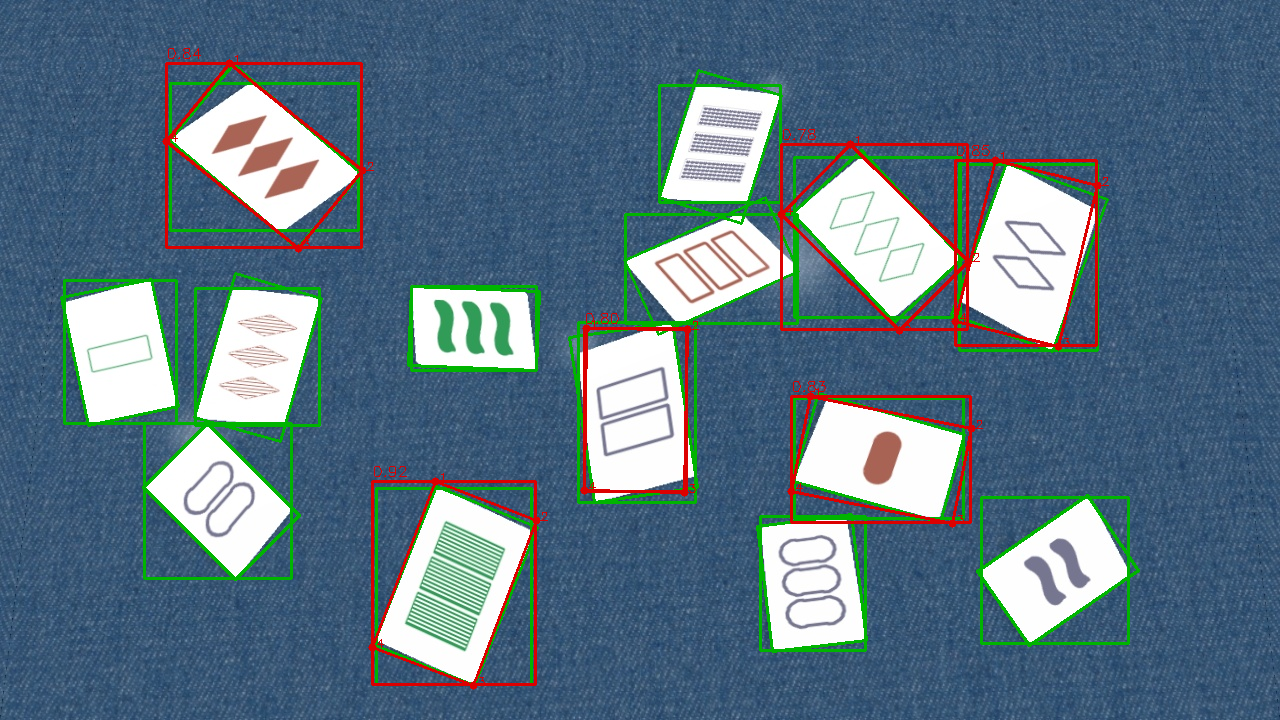

In [ ]:
score_threshold = 0.75
if checkpoint.best_model_path:
    prediction_model = load_detector(Path(checkpoint.best_model_path), repo_path)
else:
    prediction_model = model.eval()

image, target = data.val_dataset[0]
with torch.inference_mode():
    prediction = prediction_model([image.to(prediction_model.device)])[0]
display_image(prediction_overlay(image, target, prediction, score_threshold))
